# T2 — CNN treinada com ruído parcial (vs. baseline MLP)

**Melhoria proposta:** treinar a CNN com uma fração das imagens ruidosas. **Hipótese (declarada antes de medir):** a CNN treinada com ruído parcial fica tão boa quanto a CNN limpa em dados limpos e perde menos em dados ruidosos.

**Condições comparadas:** CNN com 0% / 30% / 60% de imagens ruidosas no treino (um fator por vez: só a porcentagem varia; tipo e intensidade do ruído ficam fixos), avaliada em teste limpo e em teste 100% ruidoso, 3 sementes. Para outro tipo de ruído, altere `NOISE_TYPE` e rode de novo (o CSV guarda a configuração e retoma o que já foi feito).

**Critério de empate (fixado antes da medição):** a rede com maior F1 macro vence; se a diferença ficar dentro da dispersão entre sementes, o resultado é "empate" (resultado negativo válido).

**Correções em relação à versão anterior:** mesma correção da raiz do dataset do baseline, mais teste ruidoso fixo, 3 sementes, F1 macro, parada antecipada, e teste consultado uma única vez por modelo.

In [ ]:
%pip install -q kagglehub scikit-learn pandas matplotlib

In [ ]:
import os, time, copy, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
from PIL import Image
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("numpy:", np.__version__, "· torch:", torch.__version__, "· device:", device)

# ======================================================================
# CONFIGURAÇÃO (as duas notebooks devem ter EXATAMENTE a mesma configuração
# de dados/ruído para a comparação MLP x CNN ser justa)
# ======================================================================
SEMENTES   = [48, 49, 50]   # >= 3 sementes (média ± desvio)
SPLIT_SEED = 48             # divisão treino/val/teste FIXA (igual para todas as sementes)
IMG        = 64             # lado da imagem (64x64)

NOISE_TYPE = "salt_pepper"  # "gaussian" | "salt_pepper" | "poisson" | "rotation"
# intensidade de cada ruído (imagens em [0, 1])
GAUSSIAN_STD       = 0.10
SALT_PEPPER_AMOUNT = 0.05
POISSON_PEAK       = 30.0    # menor => mais ruído
ROTATION_MAX_DEG   = 15

BATCH      = 64
LR         = 1e-3
EPOCHS_MAX = 20
PATIENCE   = 4              # parada antecipada pela perda de validação

RESULT_DIR = Path("/content/resultados") if Path("/content").exists() else Path("resultados")
RESULT_DIR.mkdir(parents=True, exist_ok=True)
(RESULT_DIR / "ckpt").mkdir(exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

numpy: 2.4.6 · torch: 2.14.1+cpu · device: cpu


## 1. Dados

In [ ]:
import kagglehub
path = kagglehub.dataset_download("dumitrux/architectural-styles-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'architectural-styles-dataset' dataset.
Path to dataset files: /kaggle/input/architectural-styles-dataset


In [ ]:
# CORREÇÃO DO BUG: o download contém DUAS pastas de topo
# (['architectural-styles-dataset', 'g-images-dataset']). Usar `path` como raiz
# do ImageFolder fazia a rede classificar essas 2 pastas em vez dos estilos.
# A raiz correta é a pasta interna, cujas subpastas são os estilos.
top = [d for d in Path(path).iterdir() if d.is_dir()]
print("Pastas de topo:", sorted(d.name for d in top))
ROOT = Path(path) / "architectural-styles-dataset"
if not ROOT.is_dir():                      # plano B: a pasta com mais subpastas
    ROOT = max(top, key=lambda d: sum(1 for x in d.iterdir() if x.is_dir()))
print("Raiz usada:", ROOT)

Pastas de topo: ['architectural-styles-dataset', 'g-images-dataset']
Raiz usada: /kaggle/input/architectural-styles-dataset/architectural-styles-dataset


In [ ]:
EXT = {".jpg", ".jpeg", ".png", ".bmp"}
CACHE = RESULT_DIR / f"cache_{IMG}.npz"

if CACHE.exists():
    d = np.load(CACHE)
    X, y, classes = d["X"], d["y"], [str(c) for c in d["classes"]]
    print("Cache carregado:", CACHE)
else:
    classes = sorted(p.name for p in ROOT.iterdir() if p.is_dir())
    Xs, ys, ignoradas = [], [], 0
    t0 = time.time()
    for ci, c in enumerate(classes):
        for p in sorted((ROOT / c).rglob("*")):
            if p.suffix.lower() not in EXT:
                continue
            try:
                im = Image.open(p)
                im.draft("RGB", (IMG * 2, IMG * 2))          # acelera JPEG grandes
                im = im.convert("RGB").resize((IMG, IMG), Image.BILINEAR)
                Xs.append(np.asarray(im, dtype=np.uint8).transpose(2, 0, 1))
                ys.append(ci)
            except Exception:
                ignoradas += 1
    X, y = np.stack(Xs), np.array(ys, dtype=np.int64)
    np.savez(CACHE, X=X, y=y, classes=np.array(classes))
    print(f"Carregadas {len(y)} imagens em {time.time()-t0:.0f}s ({ignoradas} ignoradas). Cache: {CACHE}")

num_classes = len(classes)
assert num_classes > 2, f"Só {num_classes} classes ({classes}): a raiz do dataset está errada."
print(f"{len(y)} imagens · {num_classes} classes")
print(pd.Series([classes[i] for i in y]).value_counts().to_string())

Carregadas 10113 imagens em 103s (0 ignoradas). Cache: /content/resultados/cache_64.npz
10113 imagens · 25 classes
Queen Anne architecture             720
Art Nouveau architecture            615
Art Deco architecture               566
Greek Revival architecture          523
Colonial architecture               480
Baroque architecture                456
Tudor Revival architecture          455
Beaux-Arts architecture             424
International style                 417
Ancient Egyptian architecture       406
Achaemenid architecture             392
Novelty architecture                382
Georgian architecture               381
American craftsman style            364
American Foursquare architecture    362
Russian Revival architecture        352
Palladian architecture              343
Deconstructivism                    335
Gothic architecture                 331
Postmodern architecture             322
Bauhaus architecture                315
Byzantine architecture              313
Roman

## 2. Divisão, ruídos e conjuntos de teste (idênticos aos do baseline)

In [ ]:
# Divisão ESTRATIFICADA 70/15/15, fixa (SPLIT_SEED), igual em todas as sementes e nas duas notebooks
idx = np.arange(len(y))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SPLIT_SEED)
i_va, i_te  = train_test_split(i_tmp, test_size=0.50, stratify=y[i_tmp], random_state=SPLIT_SEED)
Xtr, ytr = X[i_tr], y[i_tr]
Xva, yva = X[i_va], y[i_va]
Xte, yte = X[i_te], y[i_te]
print(f"Treino: {len(ytr)} | Validação: {len(yva)} | Teste: {len(yte)}")
maj = np.bincount(yte).max() / len(yte)
print(f"Baseline trivial (classe majoritária) no teste: acurácia = {100*maj:.2f}%  (sanidade: os modelos devem superar isto)")

# ---------------------------------------------------------------- ruídos
# Funções recebem lote float (N,3,H,W) em [0,1] e um torch.Generator (reprodutível).
def noise_gaussian(x, g):
    return (x + torch.randn(x.shape, generator=g) * GAUSSIAN_STD).clamp(0, 1)

def noise_salt_pepper(x, g):
    r = torch.rand(x.shape[0], 1, x.shape[2], x.shape[3], generator=g)   # pixel inteiro vira sal/pimenta
    x = torch.where(r < SALT_PEPPER_AMOUNT / 2, torch.zeros_like(x), x)
    x = torch.where((r >= SALT_PEPPER_AMOUNT / 2) & (r < SALT_PEPPER_AMOUNT), torch.ones_like(x), x)
    return x

def noise_poisson(x, g):
    return (torch.poisson(x * POISSON_PEAK, generator=g) / POISSON_PEAK).clamp(0, 1)

def noise_rotation(x, g):
    ang = (torch.rand(x.shape[0], generator=g) * 2 - 1) * ROTATION_MAX_DEG
    return torch.stack([TF.rotate(xi, float(a), interpolation=TF.InterpolationMode.BILINEAR, fill=0.0)
                        for xi, a in zip(x, ang)])

NOISE_FUNCS = {"gaussian": noise_gaussian, "salt_pepper": noise_salt_pepper,
               "poisson": noise_poisson, "rotation": noise_rotation}

def apply_noise(Xu8, kind, seed, chunk=512):
    """uint8 (N,3,H,W) -> uint8 com ruído, determinístico dado `seed`."""
    g = torch.Generator().manual_seed(seed)
    out = np.empty_like(Xu8)
    for i in range(0, len(Xu8), chunk):
        xb = torch.from_numpy(Xu8[i:i + chunk]).float() / 255
        xb = NOISE_FUNCS[kind](xb, g)
        out[i:i + chunk] = (xb * 255).round().clamp(0, 255).byte().numpy()
    return out

def make_partial_noisy(Xu8, kind, percent, seed):
    """Sorteia `percent`% das imagens (fixas, por semente) e aplica o ruído UMA vez."""
    if kind is None or percent == 0:
        return Xu8
    n = int(round(len(Xu8) * percent / 100))
    sel = np.random.RandomState(seed).permutation(len(Xu8))[:n]
    out = Xu8.copy()
    out[sel] = apply_noise(Xu8[sel], kind, seed + 1000)
    return out

# Conjuntos de teste: limpo + 100% ruidoso de cada tipo, FIXOS (semente própria,
# idênticos para MLP e CNN, para todas as sementes de treino).
TEST_SETS = {"limpo": Xte}
for k in NOISE_FUNCS:
    TEST_SETS[k] = apply_noise(Xte, k, SPLIT_SEED + 999)
print("Conjuntos de teste:", list(TEST_SETS))

Treino: 7079 | Validação: 1517 | Teste: 1517
Baseline trivial (classe majoritária) no teste: acurácia = 7.12%  (sanidade: os modelos devem superar isto)
Conjuntos de teste: ['limpo', 'gaussian', 'salt_pepper', 'poisson', 'rotation']


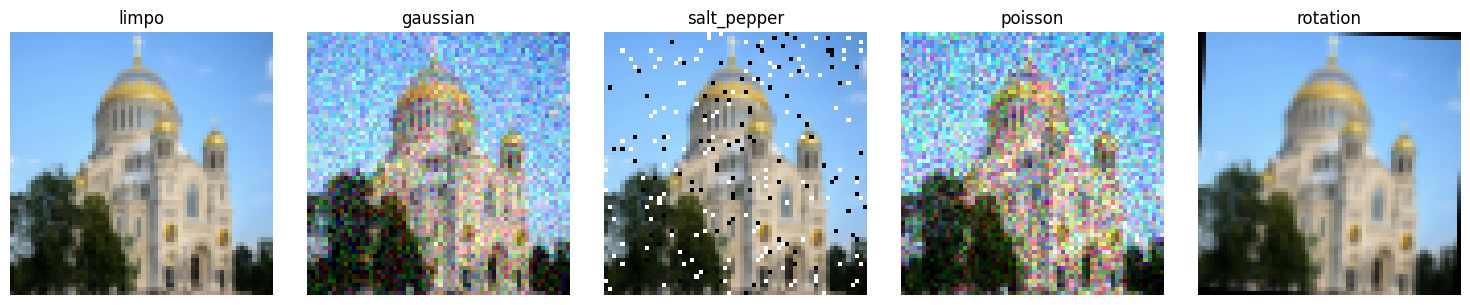

In [ ]:
# Conferência visual dos ruídos (mesma imagem de teste em cada condição)
fig, ax = plt.subplots(1, len(TEST_SETS), figsize=(3 * len(TEST_SETS), 3))
for a, (k, Xt) in zip(ax, TEST_SETS.items()):
    a.imshow(Xt[0].transpose(1, 2, 0)); a.set_title(k); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Modelo e laço de treino

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def conv_block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                                 nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(conv_block(3, 32),     # 64 -> 32
                                      conv_block(32, 64),    # 32 -> 16
                                      conv_block(64, 128))   # 16 -> 8
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3),
                                        nn.Linear(128 * 8 * 8, 256), nn.ReLU(),
                                        nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

make_cnn = lambda: SimpleCNN(num_classes)
print(sum(p.numel() for p in make_cnn().parameters()), "parâmetros")

2197529 parâmetros


In [ ]:
def to_input(xb_u8):
    """uint8 -> float normalizado em [-1, 1] (a normalização vem DEPOIS do ruído)."""
    return (xb_u8.float() / 255 - 0.5) / 0.5

@torch.no_grad()
def predict(model, Xu8, bs=256):
    model.eval()
    outs = [model(to_input(torch.from_numpy(Xu8[i:i + bs]).to(device))).cpu()
            for i in range(0, len(Xu8), bs)]
    return torch.cat(outs)

def avaliar(logits, y_true):
    pred = logits.argmax(1).numpy()
    return (pred == y_true).mean(), f1_score(y_true, pred, average="macro", zero_division=0)

def treinar(make_model, Xtr_, ytr_, seed, tag):
    """Treina com parada antecipada (perda de validação LIMPA) e guarda o melhor
    estado em disco (checkpoint). NÃO toca no conjunto de teste."""
    set_seed(seed)
    model = make_model().to(device)
    crit = nn.CrossEntropyLoss()
    opt = optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed)
    best_loss, best_state, wait, hist = float("inf"), None, 0, []
    t0 = time.time()
    for ep in range(EPOCHS_MAX):
        model.train()
        perm = torch.randperm(len(Xtr_), generator=g).numpy()
        tl, tc = 0.0, 0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            xb = to_input(torch.from_numpy(Xtr_[b]).to(device))
            yb = torch.from_numpy(ytr_[b]).to(device)
            opt.zero_grad()
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == yb).sum().item()
        lv = predict(model, Xva)
        v_loss = crit(lv, torch.from_numpy(yva)).item()
        v_acc, v_f1 = avaliar(lv, yva)
        hist.append(dict(epoca=ep + 1, train_loss=tl / len(perm), train_acc=tc / len(perm),
                         val_loss=v_loss, val_acc=v_acc, val_f1=v_f1))
        print(f"[{tag}|s{seed}] ép {ep+1:02d} | treino loss {tl/len(perm):.4f} acc {100*tc/len(perm):.1f}% "
              f"| val loss {v_loss:.4f} acc {100*v_acc:.1f}% F1 {v_f1:.3f}")
        if v_loss < best_loss - 1e-4:
            best_loss, wait = v_loss, 0
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, RESULT_DIR / "ckpt" / f"{tag}_s{seed}.pt")
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"   parada antecipada na época {ep+1}")
                break
    model.load_state_dict(best_state)
    best = min(hist, key=lambda h: h["val_loss"])
    return model, best, len(hist), time.time() - t0

def rodar(modelo, make_model, treino_ruido_pct, csv_path):
    """Treina para cada semente e avalia UMA vez no teste (limpo + 4 ruídos). Retoma do CSV."""
    done = pd.read_csv(csv_path) if csv_path.exists() else pd.DataFrame()
    tipo = NOISE_TYPE if treino_ruido_pct > 0 else "nenhum"
    tag = f"{modelo}_{tipo}{treino_ruido_pct}"
    for seed in SEMENTES:
        if len(done) and ((done.config == tag) & (done.semente == seed)).any():
            print(f"[{tag}|s{seed}] já feito, pulando"); continue
        Xn = make_partial_noisy(Xtr, NOISE_TYPE, treino_ruido_pct, seed)
        model, best, n_ep, secs = treinar(make_model, Xn, ytr, seed, tag)
        rows = []
        for cond, Xt in TEST_SETS.items():                  # teste consultado uma única vez por modelo
            acc, f1 = avaliar(predict(model, Xt), yte)
            rows.append(dict(config=tag, modelo=modelo, treino_ruido=tipo, treino_ruido_pct=treino_ruido_pct,
                             semente=seed, teste=cond, acc=acc, f1_macro=f1,
                             val_loss=best["val_loss"], val_f1=best["val_f1"],
                             epocas=n_ep, tempo_s=secs))
        done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
        done.to_csv(csv_path, index=False)                   # checkpoint dos resultados
    return done

## 4. Experimento: CNN com 0%, 30% e 60% de ruído no treino

In [ ]:
TRAIN_NOISE_PERCENTS = [0, 30, 60]
CSV_CNN = RESULT_DIR / "resultados_cnn.csv"
for pct in TRAIN_NOISE_PERCENTS:
    df_cnn = rodar("CNN", make_cnn, pct, CSV_CNN)

[CNN_nenhum0|s48] ép 01 | treino loss 3.1534 acc 9.8% | val loss 2.8699 acc 15.9% F1 0.075
[CNN_nenhum0|s48] ép 02 | treino loss 2.8516 acc 14.7% | val loss 2.7162 acc 19.0% F1 0.123
[CNN_nenhum0|s48] ép 03 | treino loss 2.7009 acc 17.7% | val loss 2.5757 acc 22.1% F1 0.162
[CNN_nenhum0|s48] ép 04 | treino loss 2.5876 acc 20.6% | val loss 2.4874 acc 24.8% F1 0.180
[CNN_nenhum0|s48] ép 05 | treino loss 2.4743 acc 23.3% | val loss 2.3845 acc 26.4% F1 0.205
[CNN_nenhum0|s48] ép 06 | treino loss 2.3985 acc 25.3% | val loss 2.4164 acc 27.0% F1 0.206
[CNN_nenhum0|s48] ép 07 | treino loss 2.3311 acc 26.3% | val loss 2.2983 acc 29.7% F1 0.244
[CNN_nenhum0|s48] ép 08 | treino loss 2.2553 acc 28.0% | val loss 2.2810 acc 30.7% F1 0.270
[CNN_nenhum0|s48] ép 09 | treino loss 2.2000 acc 30.1% | val loss 2.2747 acc 29.2% F1 0.246
[CNN_nenhum0|s48] ép 10 | treino loss 2.1504 acc 31.8% | val loss 2.1781 acc 32.2% F1 0.265
[CNN_nenhum0|s48] ép 11 | treino loss 2.0890 acc 33.3% | val loss 2.2414 acc 29.7

## 5. Resultados e comparação com o baseline

In [ ]:
def resumo(df, metrica="f1_macro"):
    g = df.groupby(["config", "teste"])[metrica].agg(["mean", "std"]).reset_index()
    g["valor"] = g.apply(lambda r: f"{r['mean']:.3f} ± {0 if pd.isna(r['std']) else r['std']:.3f}", axis=1)
    return g.pivot(index="config", columns="teste", values="valor")

df_cnn = pd.read_csv(CSV_CNN)
CSV_MLP = RESULT_DIR / "resultados_mlp.csv"          # gerado pela notebook do baseline
df_all = pd.concat([pd.read_csv(CSV_MLP), df_cnn], ignore_index=True) if CSV_MLP.exists() else df_cnn
if not CSV_MLP.exists():
    print("AVISO: resultados_mlp.csv não encontrado; rode a notebook do baseline (mesmo RESULT_DIR).")

print("F1 macro no teste (média ± desvio)"); display(resumo(df_all, "f1_macro"))
print("Acurácia no teste (média ± desvio)"); display(resumo(df_all, "acc"))
print("F1 macro na VALIDAÇÃO limpa (para escolher configuração SEM usar o teste)")
display(df_all.groupby(["config", "semente"]).val_f1.first().groupby("config").agg(["mean", "std"]).round(3))
print("Tempo médio de treino (s) e épocas:")
display(df_all.groupby(["config", "semente"])[["tempo_s", "epocas"]].first().groupby("config").mean().round(1))

AVISO: resultados_mlp.csv não encontrado; rode a notebook do baseline (mesmo RESULT_DIR).
F1 macro no teste (média ± desvio)
AVISO: resultados_mlp.csv não encontrado; rode a notebook do baseline (mesmo RESULT_DIR).
F1 macro no teste (média ± desvio)


teste,gaussian,limpo,poisson,rotation,salt_pepper
config,,,,,
CNN_nenhum0,0.109 ± 0.012,0.361 ± 0.023,0.072 ± 0.018,0.294 ± 0.014,0.081 ± 0.028
CNN_salt_pepper30,0.158 ± 0.017,0.319 ± 0.011,0.134 ± 0.022,0.295 ± 0.030,0.299 ± 0.023
CNN_salt_pepper60,0.169 ± 0.002,0.289 ± 0.005,0.147 ± 0.023,0.254 ± 0.007,0.267 ± 0.009


teste,gaussian,limpo,poisson,rotation,salt_pepper
config,,,,,
CNN_nenhum0,0.109 ± 0.012,0.361 ± 0.023,0.072 ± 0.018,0.294 ± 0.014,0.081 ± 0.028
CNN_salt_pepper30,0.158 ± 0.017,0.319 ± 0.011,0.134 ± 0.022,0.295 ± 0.030,0.299 ± 0.023
CNN_salt_pepper60,0.169 ± 0.002,0.289 ± 0.005,0.147 ± 0.023,0.254 ± 0.007,0.267 ± 0.009


Acurácia no teste (média ± desvio)
Acurácia no teste (média ± desvio)


teste,gaussian,limpo,poisson,rotation,salt_pepper
config,,,,,
CNN_nenhum0,0.152 ± 0.023,0.391 ± 0.019,0.109 ± 0.029,0.317 ± 0.010,0.123 ± 0.035
CNN_salt_pepper30,0.210 ± 0.011,0.357 ± 0.006,0.191 ± 0.016,0.325 ± 0.022,0.332 ± 0.020
CNN_salt_pepper60,0.225 ± 0.012,0.340 ± 0.002,0.204 ± 0.023,0.305 ± 0.005,0.314 ± 0.007


teste,gaussian,limpo,poisson,rotation,salt_pepper
config,,,,,
CNN_nenhum0,0.152 ± 0.023,0.391 ± 0.019,0.109 ± 0.029,0.317 ± 0.010,0.123 ± 0.035
CNN_salt_pepper30,0.210 ± 0.011,0.357 ± 0.006,0.191 ± 0.016,0.325 ± 0.022,0.332 ± 0.020
CNN_salt_pepper60,0.225 ± 0.012,0.340 ± 0.002,0.204 ± 0.023,0.305 ± 0.005,0.314 ± 0.007


... (2 outputs left out)

,mean,std
config,,
CNN_nenhum0,0.347,0.011
CNN_salt_pepper30,0.321,0.014
CNN_salt_pepper60,0.278,0.005


Tempo médio de treino (s) e épocas:
Tempo médio de treino (s) e épocas:


,tempo_s,epocas
config,,
CNN_nenhum0,1468.1,20.0
CNN_salt_pepper30,1785.1,20.0
CNN_salt_pepper60,1786.3,20.0


,tempo_s,epocas
config,,
CNN_nenhum0,1468.1,20.0
CNN_salt_pepper30,1785.1,20.0
CNN_salt_pepper60,1786.3,20.0


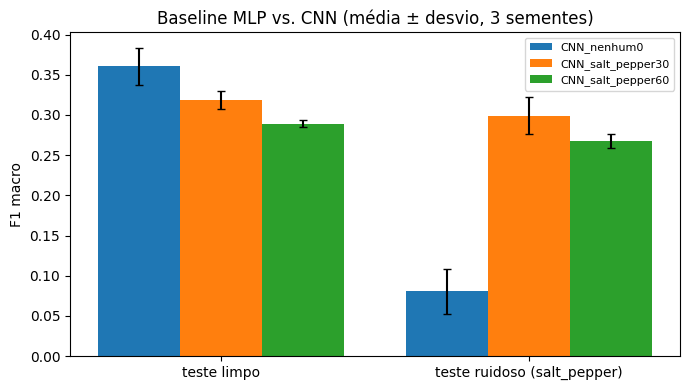

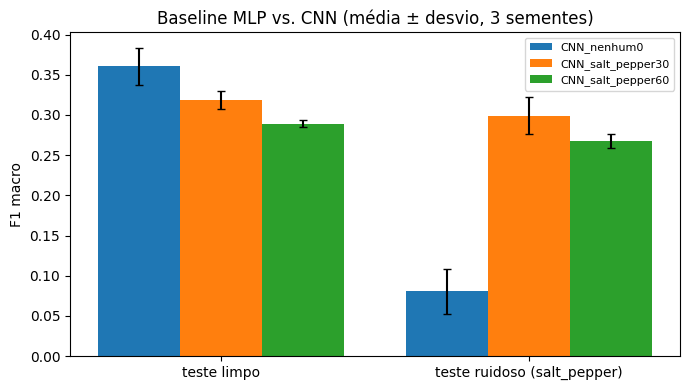

In [ ]:
# Figura principal: F1 macro (média ± desvio) em teste limpo vs. teste ruidoso do tipo treinado
conds = ["limpo", NOISE_TYPE]
cfgs = [c for c in df_all.config.unique() if (c.startswith("MLP") or NOISE_TYPE in c or c.startswith("CNN_nenhum"))]
w = 0.8 / len(cfgs)
fig, ax = plt.subplots(figsize=(7, 4))
for j, c in enumerate(cfgs):
    m = [df_all[(df_all.config == c) & (df_all.teste == t)].f1_macro.mean() for t in conds]
    s = [df_all[(df_all.config == c) & (df_all.teste == t)].f1_macro.std() for t in conds]
    ax.bar(np.arange(len(conds)) + j * w, m, w, yerr=np.nan_to_num(s), capsize=3, label=c)
ax.set_xticks(np.arange(len(conds)) + 0.4 - w / 2)
ax.set_xticklabels(["teste limpo", f"teste ruidoso ({NOISE_TYPE})"])
ax.set_ylabel("F1 macro"); ax.set_title("Baseline MLP vs. CNN (média ± desvio, 3 sementes)")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(RESULT_DIR / "figura_principal.png", dpi=200); plt.show()